In [1]:
!pip install ultralytics
import ultralytics
ultralytics.checks()
from ultralytics import YOLO

Ultralytics 8.3.59 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (4 CPUs, 31.4 GB RAM, 6037.7/8062.4 GB disk)


In [2]:
from ultralytics import YOLO

# Load YOLOv10n model from scratch
model = YOLO("yolov10n.yaml")

# Train the model
model.train(data="/kaggle/input/yolo-11-dataset-corrected/yolo 11/data.yaml", epochs=10, imgsz=512)

Ultralytics 8.3.59 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=yolov10n.yaml, data=/kaggle/input/yolo-11-dataset-corrected/yolo 11/data.yaml, epochs=10, time=None, patience=100, batch=16, imgsz=512, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_label

100%|██████████| 755k/755k [00:00<00:00, 4.13MB/s]


Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1      9856  ultralytics.nn.modules.block.SCDown          [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1     36096  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 16.0MB/s]


AMP: checks passed ✅


train: Scanning /kaggle/input/yolo-11-dataset-corrected/yolo 11/train/labels... 18228 images, 0 backgrounds, 0 corrupt: 100%|██████████| 18228/18228 [00:59<00:00, 307.10it/s]


... (33 outputs left out)


10 epochs completed in 0.517 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 5.7MB
Optimizer stripped from runs/detect/train/weights/best.pt, 5.7MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.59 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10n summary (fused): 285 layers, 2,695,196 parameters, 0 gradients, 8.2 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 41/41 [00:07<00:00,  5.43it/s]


                   all       1302       1302      0.584      0.859      0.689      0.673
                  fake        651        651      0.571      0.907      0.687      0.684
                  real        651        651      0.596      0.811      0.692      0.661
Speed: 0.1ms preprocess, 1.9ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to runs/detect/train


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b08804ed6f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [6]:
# Load the trained model
model = YOLO("/kaggle/working/runs/detect/train/weights/best.pt")  # Adjust path to your weights


In [9]:
# Perform inference on the test dataset
results = model.predict(source="/kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images", imgsz=512)




WARNING ⚠️ inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1302 /kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/easy_1003_jpg.rf.99a96dc79edd0a297cbb8157d8c938ce.jpg: 512x512 1 fake, 1 real, 13.0ms
image 2/1302 /kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/easy_1008_jpg.rf.053facd92a2344bf5b2a1b21b2d349ec.jpg: 512x512 1 fake, 1 real, 10.6ms
image 3/1302 /kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/easy_1014_jpg.rf.1da1434a35eadf49a919b657568888d8.jpg: 512x512 1 

In [8]:
# Display prediction results
results.show()  # Visualize in the notebook
results.save(save_dir="/kaggle/working/test_results")  # Save results to a directory


AttributeError: 'list' object has no attribute 'show'

In [10]:
# Evaluate the model on the test dataset
metrics = model.val(data="/kaggle/input/yolo-11-dataset-corrected/yolo 11/data.yaml", imgsz=512)

# Print evaluation metrics
print(metrics)


Ultralytics 8.3.59 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15095MiB)


val: Scanning /kaggle/input/yolo-11-dataset-corrected/yolo 11/valid/labels... 1302 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1302/1302 [00:02<00:00, 644.18it/s]

val: WARNING ⚠️ Cache directory /kaggle/input/yolo-11-dataset-corrected/yolo 11/valid is not writeable, cache not saved.



/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 82/82 [00:09<00:00,  8.40it/s]


                   all       1302       1302      0.584      0.859       0.69      0.673
                  fake        651        651      0.571      0.908      0.688      0.685
                  real        651        651      0.596      0.811      0.692      0.661
Speed: 0.2ms preprocess, 3.3ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to runs/detect/val
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7b0880f1e050>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.

In [12]:
!cp -r /content/runs/detect/predict '/kaggle/working/'


cp: cannot stat '/content/runs/detect/predict': No such file or directory



image 1/1 /kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/easy_1160_jpg.rf.25aeccbe128e5ee8b70644b04a9eda5a.jpg: 640x640 2 persons, 9.4ms
Speed: 2.5ms preprocess, 9.4ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)


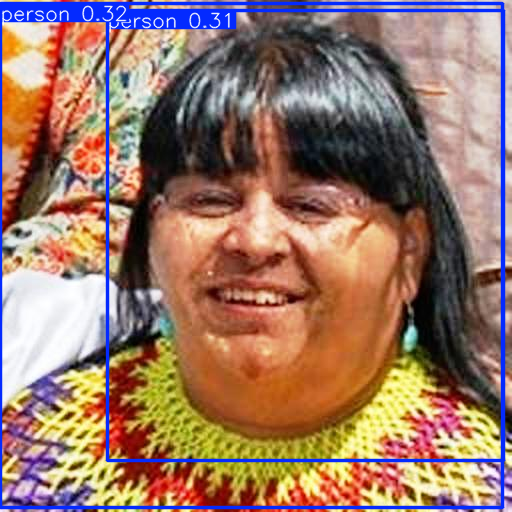

In [3]:
from ultralytics import YOLO

# Load a pre-trained YOLOv10n model
model = YOLO("/kaggle/working/yolo11n.pt")

# Perform object detection on an image
results = model("/kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/easy_1160_jpg.rf.25aeccbe128e5ee8b70644b04a9eda5a.jpg")

# Display the results
results[0].show()

In [4]:
!yolo task=detect mode=predict model=/kaggle/working/runs/detect/train/weights/best.pt conf=0.55 source='/kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/easy_1120_jpg.rf.7450bf934da7544d5002a83cce0dd57f.jpg'

/usr/lib/python3.10/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


Ultralytics 8.3.59 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10n summary (fused): 285 layers, 2,695,196 parameters, 0 gradients, 8.2 GFLOPs

image 1/1 /kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/easy_1120_jpg.rf.7450bf934da7544d5002a83cce0dd57f.jpg: 512x512 1 real, 11.1ms
Speed: 1.9ms preprocess, 11.1ms inference, 24.8ms postprocess per image at shape (1, 3, 512, 512)
Results saved to runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [18]:
!yolo task=detect mode=predict model=/kaggle/working/runs/detect/train/weights/best.pt conf=0.55 source='/kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/easy_1138_jpg.rf.e60adab26e741f2a599bf0aeaac33e19.jpg'

Ultralytics 8.3.59 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10n summary (fused): 285 layers, 2,695,196 parameters, 0 gradients, 8.2 GFLOPs

image 1/1 /kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/easy_1138_jpg.rf.e60adab26e741f2a599bf0aeaac33e19.jpg: 512x512 1 fake, 11.7ms
Speed: 2.0ms preprocess, 11.7ms inference, 25.0ms postprocess per image at shape (1, 3, 512, 512)
Results saved to runs/detect/predict2
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [19]:
!yolo task=detect mode=predict model=/kaggle/working/runs/detect/train/weights/best.pt conf=0.55 source='/kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/hard_1045_jpg.rf.2bc48bc9ab817482266ecdedcd4d84fc.jpg'

Ultralytics 8.3.59 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10n summary (fused): 285 layers, 2,695,196 parameters, 0 gradients, 8.2 GFLOPs

image 1/1 /kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/hard_1045_jpg.rf.2bc48bc9ab817482266ecdedcd4d84fc.jpg: 512x512 1 real, 11.3ms
Speed: 1.7ms preprocess, 11.3ms inference, 25.3ms postprocess per image at shape (1, 3, 512, 512)
Results saved to runs/detect/predict3
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [20]:
!yolo task=detect mode=predict model=/kaggle/working/runs/detect/train/weights/best.pt conf=0.55 source='/kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/hard_fake_443_jpg.rf.a6bde1ef56a7ab601820f7ded45ce212.jpg'

Ultralytics 8.3.59 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15095MiB)
YOLOv10n summary (fused): 285 layers, 2,695,196 parameters, 0 gradients, 8.2 GFLOPs

image 1/1 /kaggle/input/yolo-11-dataset-corrected/yolo 11/test/images/hard_fake_443_jpg.rf.a6bde1ef56a7ab601820f7ded45ce212.jpg: 512x512 1 fake, 11.8ms
Speed: 1.7ms preprocess, 11.8ms inference, 25.2ms postprocess per image at shape (1, 3, 512, 512)
Results saved to runs/detect/predict4
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [21]:
import shutil

# Zip the 'runs' directory or any specific folder
shutil.make_archive("output_files", 'zip', "./runs")

'/kaggle/working/output_files.zip'

In [22]:
from IPython.display import FileLink

# Generate a download link
FileLink("output_files.zip")

/kaggle/working/output_files.zip